Predicting Customer Churn in Telecom Industry using Machine Learning

Churn is a one of the biggest problem in the telecom industry. Research has shown that the average monthly churn rate among the top 4 wireless carriers in the US is about 1.9% - 2%. Hence, in this project I will be building several ML models that can take as inputs different features related to a customer and predict whether he/she will churn or not in the near future.

Customers who left within the last month – the column is called Churn
Services that each customer has signed up for – phone, multiple lines, internet, online security, online backup, device protection, tech support, and streaming TV and movies
Customer account information – how long they’ve been a customer, contract, payment method, paperless billing, monthly charges, and total charges
Demographic info about customers – gender, age range, and if they have partners and dependents

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('white')


In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split


In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, recall_score, auc, roc_curve

ModuleNotFoundError: No module named 'xgboost'

In [4]:
!pip install xgboost

   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/101.7 MB 325.1 kB/s eta 0:05:13
   ---------------------------------------- 0.1/101.7 MB 375.8 kB/s eta 0:04:31
   ---------------------------------------- 0.1/101.7 MB 590.8 kB/s eta 0:02:52
   ---------------------------------------- 0.2/101.7 MB 857.5 kB/s eta 0:01:59
   ---------------------------------------- 0.2/101.7 MB 935.2 kB/s eta 0:01:49
   ---------------------------------------- 0.5/101.7 MB 1.7 MB/s eta 0:01:01
   ---------------------------------------- 0.6/101.7 MB 1.8 MB/s eta 0:00:55
   ---------------------------------------- 1.0/101.7 MB 2.7 MB/s eta 0:00:38
   ---------------------------------------- 1.0/101.7 MB 2.7 MB/s eta 0:00:38
    --------------------------------------- 1.4/101.7 MB 3.2 MB/s eta 0:00:32
    --------------------------------------- 1.4/101.7 MB 3.2 MB/s et

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, recall_score, auc, roc_curve

In [6]:
data = pd.read_csv(r"C:\Users\DELL\Downloads\WA_Fn-UseC_-Telco-Customer-Churn.csv")
data

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes


Data Validation

Remove Unnecessary Columns

In [7]:
data = data.drop(columns=['customerID'])
data

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes


In [8]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   object 
 16  PaymentMethod     7043 non-null   object 


In [9]:
data['TotalCharges'] = pd.to_numeric(data['TotalCharges'], errors= 'coerce')

In [10]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   object 
 16  PaymentMethod     7043 non-null   object 


Check for Missing Values

In [11]:
data.isnull().sum()

gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [12]:
data.dropna(inplace=True)

In [13]:
data.isnull().sum()

gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [14]:
data

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.50,No
7039,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.90,No
7040,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.60,Yes


Check fo Dataset Imbalance

In [15]:
data['Churn'].value_counts()

Churn
No     5163
Yes    1869
Name: count, dtype: int64

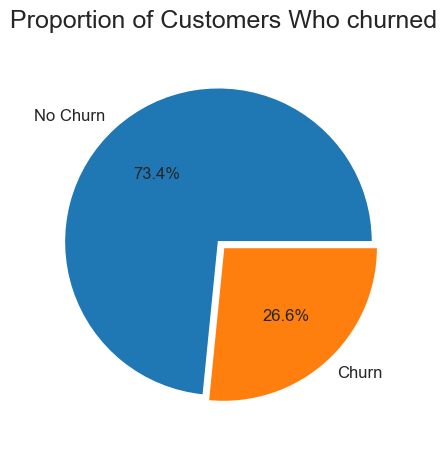

In [16]:
plt.figure(figsize=(8,5))

plt.pie(data['Churn'].value_counts(), explode=(0.05,0), labels=['No Churn', 'Churn'], autopct = '%1.1f%%', textprops={'fontsize' : 12})
plt.title('Proportion of Customers Who churned', size=18, pad=20)
plt.show()

Convert Targets to Binary

ML models work much better with numeric data, especially when it is predicting a variable in supervised learning. Hence, I would like to convert the data in the Churn column to 0s (No) and 1s (Yes). For that, I will be using a separate variable.

In [17]:
data_2 = data.copy()
data_2['Churn'] = data_2['Churn'].map({'Yes':1, 'No': 0})

In [18]:
data_2['Churn']

0       0
1       0
2       1
3       0
4       1
       ..
7038    0
7039    0
7040    0
7041    1
7042    0
Name: Churn, Length: 7032, dtype: int64

In [19]:
data_2

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.50,0
7039,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.90,0
7040,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,0
7041,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.60,1


One Hot Encoding


For our model building process, it is important we turn the categorical variables into numeric. However, since we need the original dataset for our EDA, I will create a separate dataset with one-hot encoded variables.

Also, I will be creating another dataset dropping the first dummy column of each variable as it would be adding unnecessary columns that would also create multicollinearity among the columns.

In [20]:
#dummy data

data_with_dummies = pd.get_dummies(data_2)
data_with_dummies.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Female,gender_Male,Partner_No,Partner_Yes,Dependents_No,...,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaperlessBilling_No,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,True,False,False,True,True,...,False,True,False,False,False,True,False,False,True,False
1,0,34,56.95,1889.50,0,False,True,True,False,True,...,False,False,True,False,True,False,False,False,False,True
2,0,2,53.85,108.15,1,False,True,True,False,True,...,False,True,False,False,False,True,False,False,False,True
3,0,45,42.30,1840.75,0,False,True,True,False,True,...,False,False,True,False,True,False,True,False,False,False
4,0,2,70.70,151.65,1,True,False,True,False,True,...,False,True,False,False,False,True,False,False,True,False


In [21]:
# dummy data with drop_first
data_dummy_drop_first = pd.get_dummies(data_2, drop_first=True)
data_dummy_drop_first.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,False,True,False,False,True,...,False,False,False,False,False,False,True,False,True,False
1,0,34,56.95,1889.50,0,True,False,False,True,False,...,False,False,False,False,True,False,False,False,False,True
2,0,2,53.85,108.15,1,True,False,False,True,False,...,False,False,False,False,False,False,True,False,False,True
3,0,45,42.30,1840.75,0,True,False,False,False,True,...,False,False,False,False,True,False,False,False,False,False
4,0,2,70.70,151.65,1,False,False,False,True,False,...,False,False,False,False,False,False,True,False,True,False


In [22]:
# dummy data with drop_first
data_dummy_drop_first = pd.get_dummies(data_2, drop_first=True)
data_dummy_drop_first.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,False,True,False,False,True,...,False,False,False,False,False,False,True,False,True,False
1,0,34,56.95,1889.50,0,True,False,False,True,False,...,False,False,False,False,True,False,False,False,False,True
2,0,2,53.85,108.15,1,True,False,False,True,False,...,False,False,False,False,False,False,True,False,False,True
3,0,45,42.30,1840.75,0,True,False,False,False,True,...,False,False,False,False,True,False,False,False,False,False
4,0,2,70.70,151.65,1,False,False,False,True,False,...,False,False,False,False,False,False,True,False,True,False


As we can see, all the categorical variables have been one-hot encoded.

Exploratory Data Analysis (EDA)

Correlation with Churn


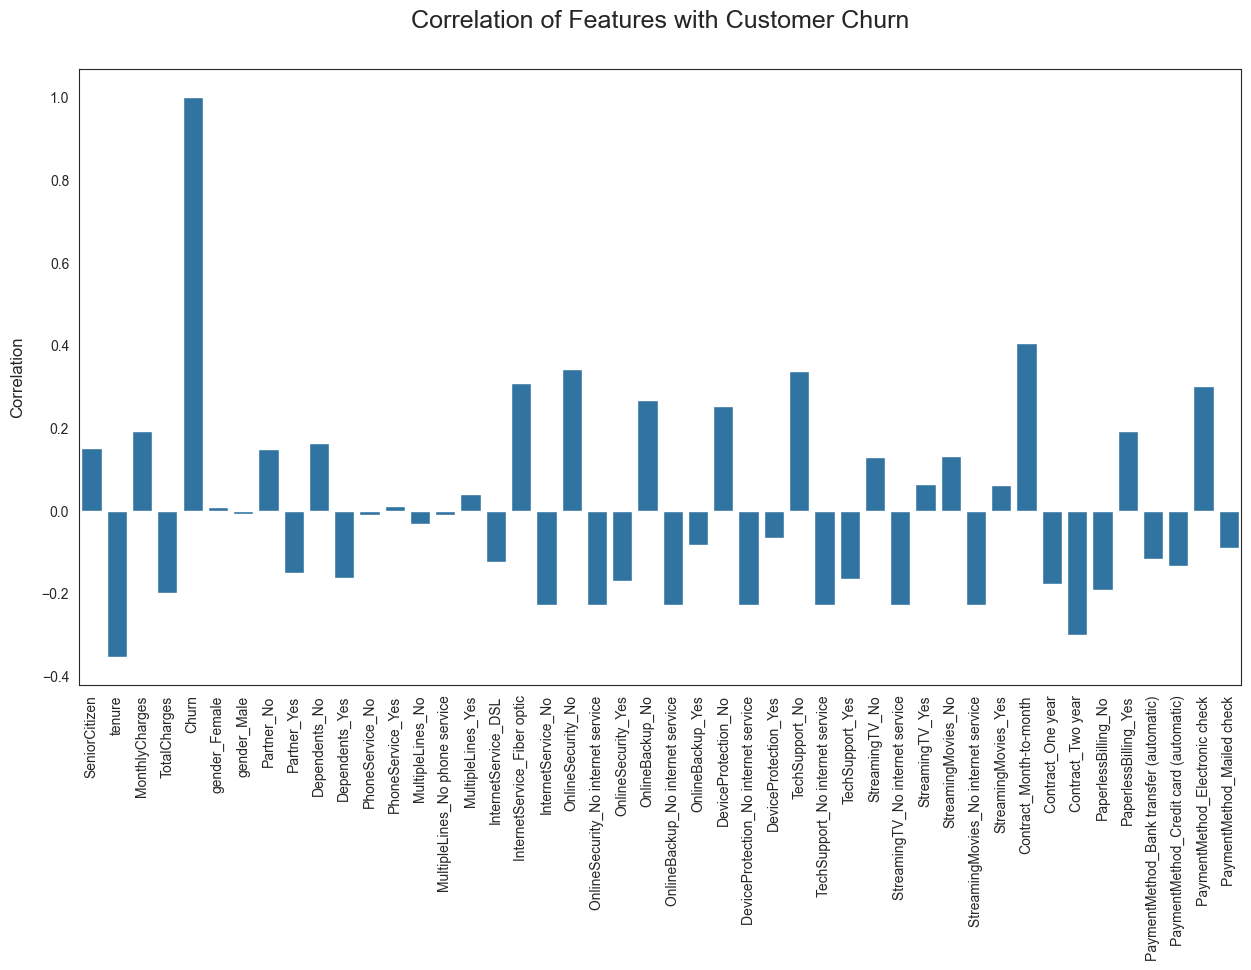

In [24]:
plt.figure(figsize=(15,8))

sns.barplot(x=data_with_dummies.columns.values, y=data_with_dummies.corr()['Churn'])
plt.ylabel('Correlation', size=12, labelpad=12)
plt.xticks(rotation=90)
plt.title('Correlation of Features with Customer Churn', size=18, pad=30)
plt.show()

From the above graph, we can see that month to month contracts, no online security, no online backup, no device security and no tech support seem to raise the churn rate, among other features. This is expected as people will be less interested in a company without proper online support. Moreover, senior citizens also churn a lot, which could simply mean that they are dead.

On the other hand, churn is negatively correlated with tenure lengths and lengthier contracts. This could be because these people invested a lot in their services that they are unwilling to back off now. Also, people with dependents and partners also seem to churn less frequently, maybe because they stay with the company for affordable family packages.

Customer Tenure Length

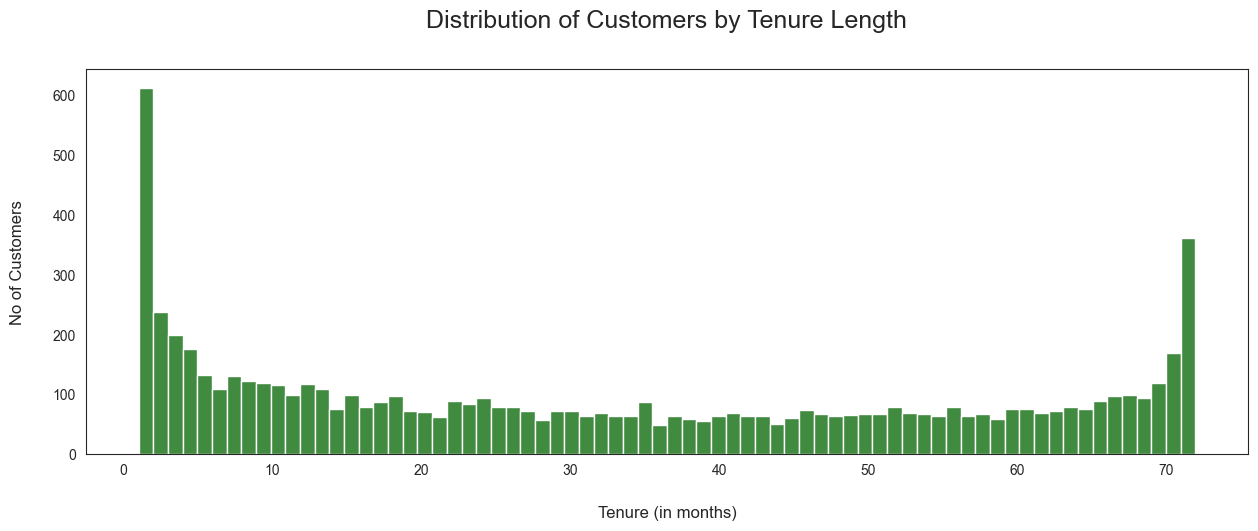

In [25]:
fig, ax = plt.subplots(figsize=(15,5))

sns.histplot(data=data, x='tenure', color='darkgreen', bins=72, ax=ax)
plt.xlabel('Tenure (in months)', size=12, labelpad=20)
plt.ylabel('No of Customers', size=12, labelpad=20)
plt.title('Distribution of Customers by Tenure Length', size=18, pad=30)
plt.show()

The histogram above shows that most of the customers have been with the company for only a month while quite a few of them stayed for a maximum of 72 months. This could be because each customer have different lengths of contracts that affect how easy/hard it is to stay or leave the company.

Contract Types

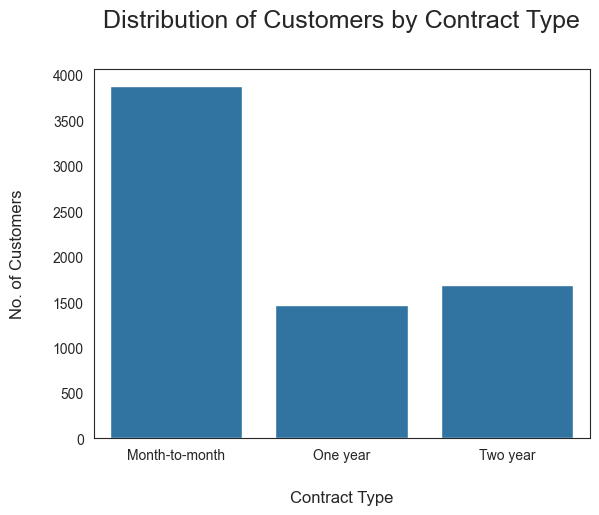

In [26]:
sns.countplot(data=data, x='Contract')
plt.ylabel('No. of Customers', size=12,  labelpad=20)
plt.xlabel('Contract Type', size=12, labelpad=20)
plt.title('Distribution of Customers by Contract Type', size=18, pad=30)
plt.show()

From the graph, it is visible that most of the customers have a month-to-month contract with the company, while the number of people with one and two year contracts are almost equal.

Tenure by Contract Type

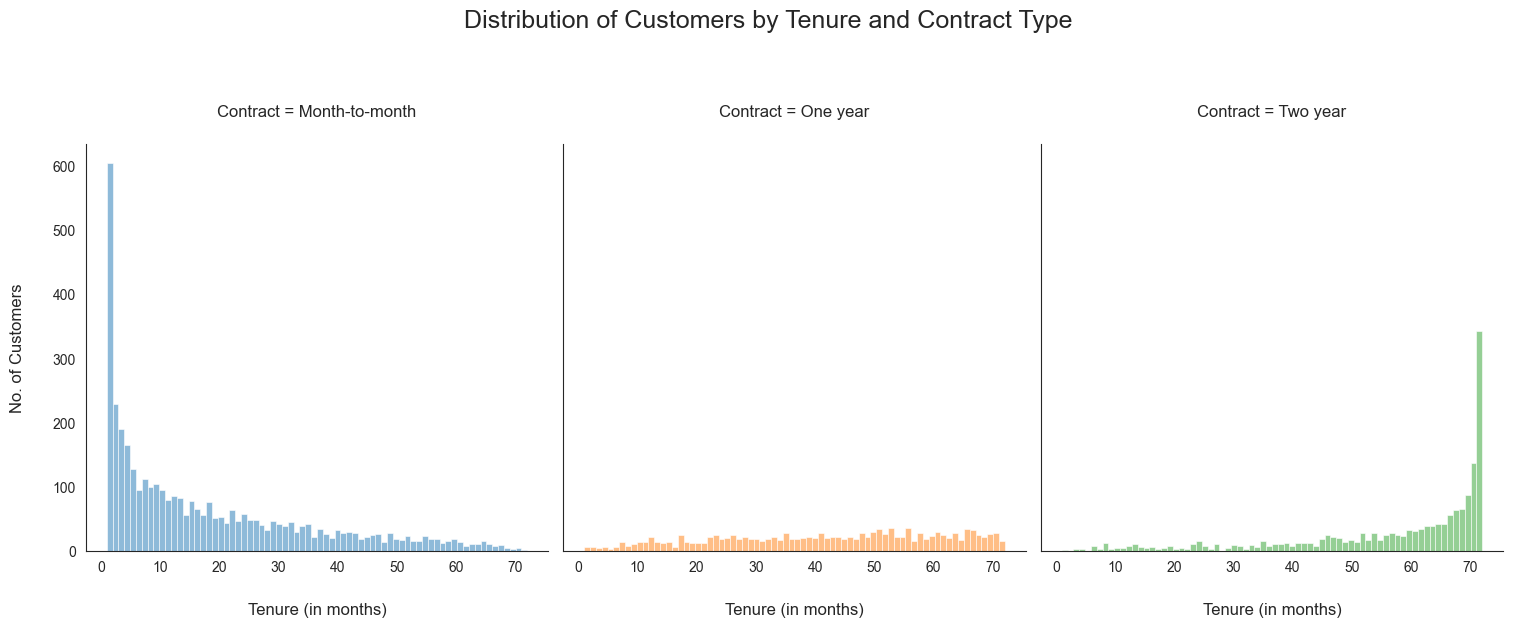

In [27]:
plot = sns.displot(data=data, x='tenure', col='Contract', bins=72, hue='Contract', height=5, legend=False)

plot.set_axis_labels(x_var='Tenure (in months)', y_var='No. of Customers', size=12, labelpad=20)
plot.set_titles(size=12, pad=20)
plot.fig.suptitle('Distribution of Customers by Tenure and Contract Type', size=18, y=1.2)

plt.show()

As can be seen, most of the monthly contracts only lasts for less than 2 months, while the 2 year ones end up lasting for more than 70 months. This goes on to show that customers who take a longer contract are more loyal to the company and tend to stay with it for a longer period of time.

Services used

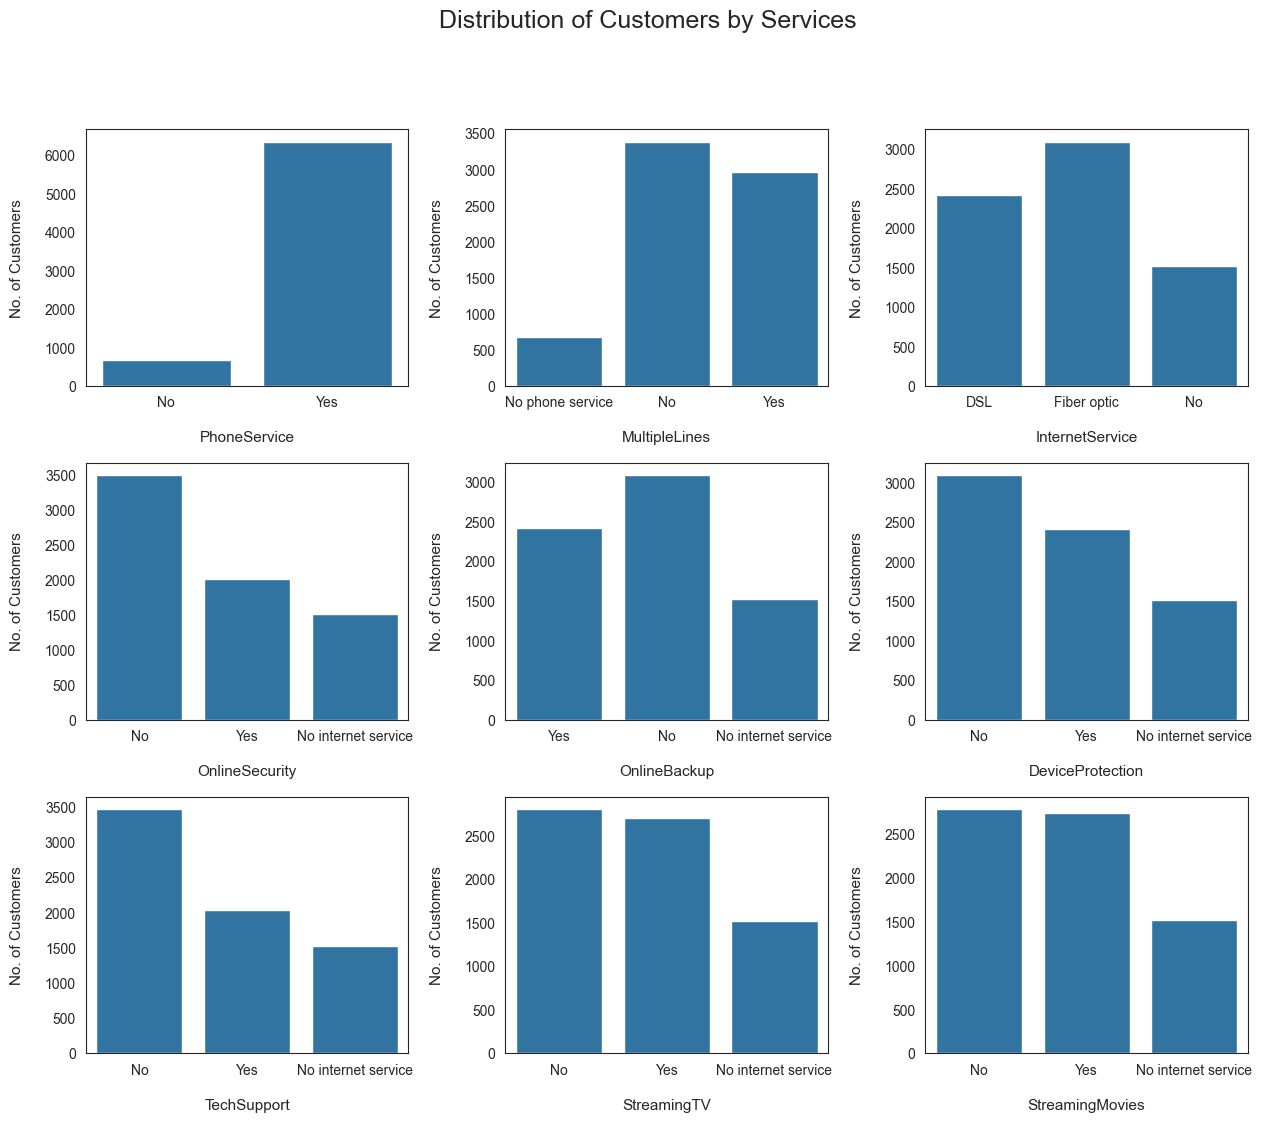

In [28]:
services = ['PhoneService','MultipleLines','InternetService','OnlineSecurity',
           'OnlineBackup','DeviceProtection','TechSupport','StreamingTV','StreamingMovies']

fig, axes = plt.subplots(3, 3, figsize=(15,12))
plt.subplots_adjust(wspace=0.3, hspace=0.3)

for i in range(len(services)):
    if i < 3:
        sns.countplot(data=data, x=services[i], ax=axes[0,i])
        axes[0,i].set_xlabel(services[i], size=11, labelpad=15)
        axes[0,i].set_ylabel('No. of Customers', size=11, labelpad=15)

    elif 3 <= i < 6:
        sns.countplot(data=data, x=services[i], ax=axes[1,i-3])
        axes[1,i-3].set_xlabel(services[i], size=11, labelpad=15)
        axes[1,i-3].set_ylabel('No. of Customers', size=11, labelpad=15)

    else:
        sns.countplot(data=data, x=services[i], ax=axes[2,i-6])
        axes[2,i-6].set_xlabel(services[i], size=11, labelpad=15)
        axes[2,i-6].set_ylabel('No. of Customers', size=11, labelpad=15)

plt.suptitle('Distribution of Customers by Services', size=18)
plt.show()

Churn vs. Tenure Length

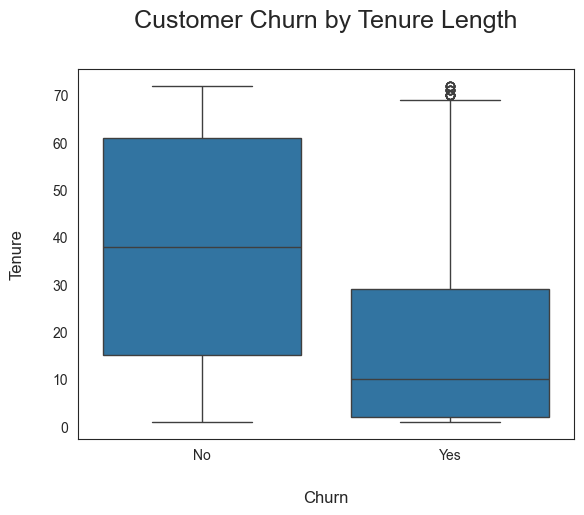

In [29]:
sns.boxplot(data=data, x='Churn', y='tenure')
plt.xlabel('Churn', size=12, labelpad=20)
plt.ylabel('Tenure', size=12, labelpad=20)
plt.title('Customer Churn by Tenure Length', size=18, pad=30)
plt.show()

As expected, customers that churn usually stay for a short amount of time with the company and vice versa.

Churn vs. Contract Type

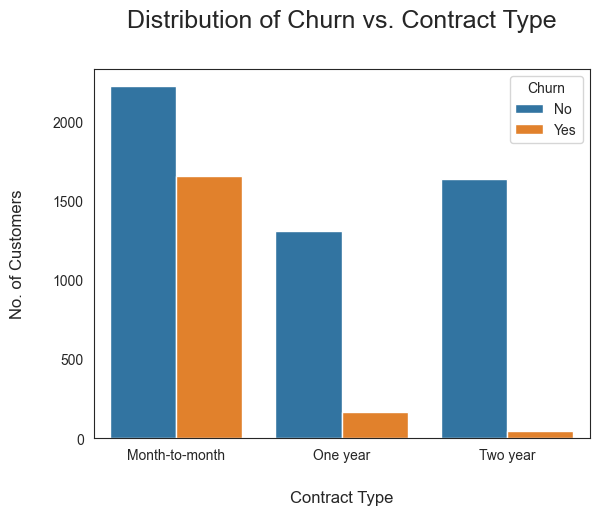

In [30]:
sns.countplot(data=data, x='Contract', hue='Churn')
plt.xlabel('Contract Type', size=12, labelpad=20)
plt.ylabel('No. of Customers', size=12, labelpad=20)
plt.title('Distribution of Churn vs. Contract Type', size=18, pad=30)
plt.show()

Similar to what we predicted, the customers who have a month to month contract have a very high churn rate compared to the ones with 2-year contracts.

Churn vs. Dependents and Partners

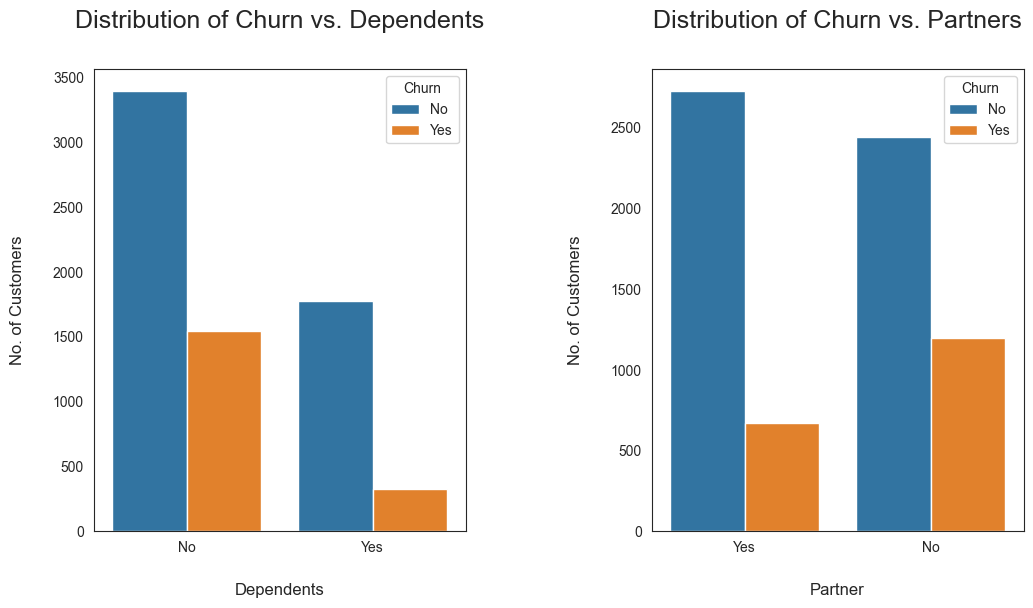

In [31]:
plt.figure(figsize=(12, 6))

plt.subplot(1,2,1)
sns.countplot(data=data, x='Dependents', hue='Churn')
plt.xlabel('Dependents', size=12, labelpad=20)
plt.ylabel('No. of Customers', size=12, labelpad=20)
plt.title('Distribution of Churn vs. Dependents', size=18, pad=30)

plt.subplot(1,2,2)
sns.countplot(data=data, x='Partner', hue='Churn')
plt.xlabel('Partner', size=12, labelpad=20)
plt.ylabel('No. of Customers', size=12, labelpad=20)
plt.title('Distribution of Churn vs. Partners', size=18, pad=30)

plt.subplots_adjust(wspace=0.5)
plt.show()

As previously noted, the presence of dependents and partners has a negative correlation with churn, as people with a family tends to churn less and stay loyal to the company.

Churn vs. Senior Citizen

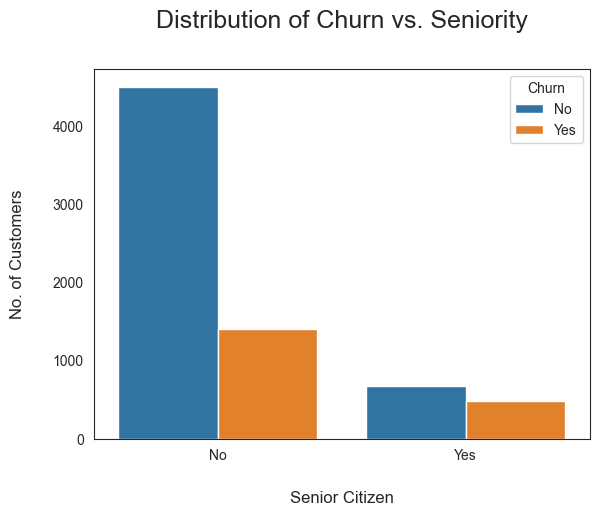

In [32]:
sns.countplot(data=data, x='SeniorCitizen', hue='Churn')
plt.xlabel('Senior Citizen', size=12, labelpad=20)
plt.ylabel('No. of Customers', size=12, labelpad=20)
plt.xticks(ticks=[0, 1], labels=['No', 'Yes'])
plt.title('Distribution of Churn vs. Seniority', size=18, pad=30)
plt.show()

As seen above, a much higher proportion (>40%) of the customers who are senior citizens tend to churn more. As assumed earlier, it could simply mean that the customers have expired due to natural elderly reasons

Churn vs Monthly Charges

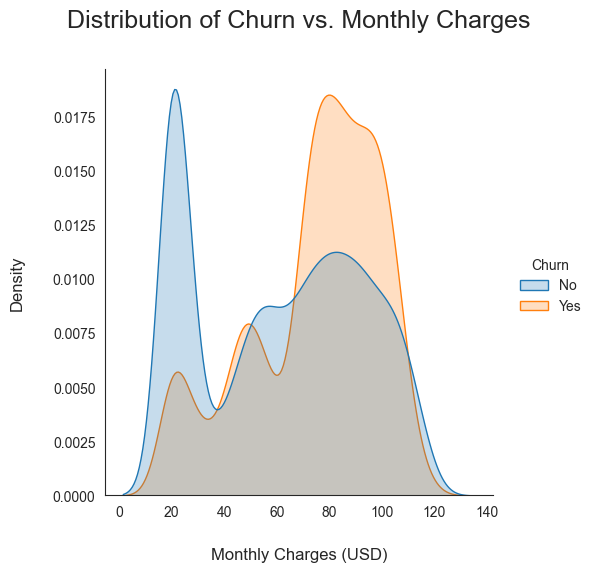

In [33]:
sns.displot(data=data, x='MonthlyCharges', hue='Churn', kind='kde', fill=True, common_norm=False)
plt.xlabel('Monthly Charges (USD)', size=12, labelpad=20)
plt.ylabel('Density', size=12, labelpad=20)
plt.title('Distribution of Churn vs. Monthly Charges', size=18, pad=30)
plt.show()


As expected previously, more people tend to churn when the monthly charges are higher.

Data Preprocessing

In [35]:
model_data = data_dummy_drop_first.copy()

scaler = StandardScaler()

model_data['tenure'] = scaler.fit_transform(data_dummy_drop_first[['tenure']])
model_data['MonthlyCharges'] = scaler.fit_transform(data_dummy_drop_first[['MonthlyCharges']])
model_data['TotalCharges'] = scaler.fit_transform(data_dummy_drop_first[['TotalCharges']])

In [36]:
model_data.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,-1.280248,-1.161694,-0.994194,0,False,True,False,False,True,...,False,False,False,False,False,False,True,False,True,False
1,0,0.064303,-0.260878,-0.173740,0,True,False,False,True,False,...,False,False,False,False,True,False,False,False,False,True
2,0,-1.239504,-0.363923,-0.959649,1,True,False,False,True,False,...,False,False,False,False,False,False,True,False,False,True
3,0,0.512486,-0.747850,-0.195248,0,True,False,False,False,True,...,False,False,False,False,True,False,False,False,False,False
4,0,-1.239504,0.196178,-0.940457,1,False,False,False,True,False,...,False,False,False,False,False,False,True,False,True,False


In [37]:
model_data.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn
count,7032.000000,7.032000e+03,7.032000e+03,7.032000e+03,7032.000000
mean,0.162400,-1.126643e-16,6.062651e-17,-1.119064e-16,0.265785
std,0.368844,1.000071e+00,1.000071e+00,1.000071e+00,0.441782
min,0.000000,-1.280248e+00,-1.547283e+00,-9.990692e-01,0.000000
25%,0.000000,-9.542963e-01,-9.709769e-01,-8.302488e-01,0.000000
50%,0.000000,-1.394171e-01,1.845440e-01,-3.908151e-01,0.000000
75%,0.000000,9.199259e-01,8.331482e-01,6.668271e-01,1.000000
max,1.000000,1.612573e+00,1.793381e+00,2.824261e+00,1.000000


Train Test Split

In [39]:
y = model_data['Churn'].values
X= model_data.drop(columns=['Churn'])

In [40]:
X.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,-1.280248,-1.161694,-0.994194,False,True,False,False,True,False,...,False,False,False,False,False,False,True,False,True,False
1,0,0.064303,-0.260878,-0.173740,True,False,False,True,False,False,...,False,False,False,False,True,False,False,False,False,True
2,0,-1.239504,-0.363923,-0.959649,True,False,False,True,False,False,...,False,False,False,False,False,False,True,False,False,True
3,0,0.512486,-0.747850,-0.195248,True,False,False,False,True,False,...,False,False,False,False,True,False,False,False,False,False
4,0,-1.239504,0.196178,-0.940457,False,False,False,True,False,False,...,False,False,False,False,False,False,True,False,True,False


In [41]:
y

array([0, 0, 1, ..., 0, 1, 0], dtype=int64)

In [42]:
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [43]:
print(x_train.shape, x_test.shape)

(5625, 30) (1407, 30)


In [44]:
print(y_train.sum())
print(y_test.sum())

1495
374


Both the classes are imbalanced as they have 27% rows from 'churn' and 73% rows from 'not churn' class. Imbalance in the test set is not much of a concern but that of the train set is since it can cause overfitting and poor recall score. Recall score is of utmost importance here since the cost of false negative in our project is much higher.

Over Sampling

As we have seen previously, the dataset is overly unbalanced as there are more observations from the 'no churn' class than the 'churn' class. Hence, I will be oversampling the minority class so that the total observations in both the classes are equal, without the loss of any valuable data.

For that, I will be using the SMOTE technique which synthesizes new examples for the minority class without causing data overfitting.

In [45]:
sm = SMOTE(random_state=42)
x_res, y_res = sm.fit_resample(x_train, y_train)

NameError: name 'SMOTE' is not defined

In [46]:
from imblearn.over_sampling import SMOTE

In [47]:
sm = SMOTE(random_state=42)
x_res, y_res = sm.fit_resample(x_train, y_train)

In [48]:
x_res.shape

(8260, 30)

In [49]:
y_res.sum()

4130

We can see that we have increased our dataset from 5625 rows to 8260 and also the class is now balanced.

With that we have completed all the necessary data preprocessing steps and can move towards building ML models for churn prediction.

Logistic Regression

In [50]:
log_model = LogisticRegression()
log_model.fit(x_res, y_res)

LogisticRegression()

In [51]:
log_preds = log_model.predict(x_test)
print('test acc:', accuracy_score(y_test, log_preds))
print('recall:', recall_score(y_test, log_preds))

test acc: 0.7434257285003554
recall: 0.7299465240641712


The logistic regression has given us a test accuracy of 75% and a good recall of 0.73. Let's look at the coefficients of the model to eliminate any irrelevant columns.

Create Summary Table

In [52]:
summary_table = pd.DataFrame(data=x_res.columns.values, columns=['Feature Names'])
summary_table

,Feature Names
0,SeniorCitizen
1,tenure
2,MonthlyCharges
3,TotalCharges
4,gender_Male
5,Partner_Yes
6,Dependents_Yes
7,PhoneService_Yes
8,MultipleLines_No phone service
9,MultipleLines_Yes


In [53]:
summary_table['Coefficients'] = np.transpose(log_model.coef_)

# add the intercept
# shift all rows 1 down and add at the beginning
summary_table.index = summary_table.index + 1
summary_table.loc[0] = ['Intercept', log_model.intercept_[0]]

In [54]:
summary_table = summary_table.sort_index()
summary_table

,Feature Names,Coefficients
0,Intercept,-11.067280
1,SeniorCitizen,0.013000
2,tenure,-1.633424
3,MonthlyCharges,-8.371179
4,TotalCharges,0.791727
5,gender_Male,0.196545
6,Partner_Yes,0.183430
7,Dependents_Yes,-0.205010
8,PhoneService_Yes,3.609746
9,MultipleLines_No phone service,-1.285834


Interpret Results

In [56]:
summary_table['Odds Ratio'] = np.exp(summary_table['Coefficients'])
summary_table.sort_values(by=['Odds Ratio'], ascending=False)

,Feature Names,Coefficients,Odds Ratio
11,InternetService_Fiber optic,7.702047,2212.873458
8,PhoneService_Yes,3.609746,36.956648
24,StreamingMovies_Yes,3.035304,20.807301
22,StreamingTV_Yes,2.916887,18.483657
10,MultipleLines_Yes,1.754908,5.782916
18,DeviceProtection_Yes,1.435299,4.200903
16,OnlineBackup_Yes,1.302026,3.676737
14,OnlineSecurity_Yes,0.991852,2.696223
20,TechSupport_Yes,0.968984,2.635265
29,PaymentMethod_Electronic check,0.926146,2.524759


A feature is not particularly important if its:

coefficient is around 0
odds ratio is around 1
A weight of 0 implies that no matter the feature value, we will multiply it by 0 in the model.

For a unit change in the standardized feature, the odds increase by a multiple equal to the odds ratio. Hence, 1 implies no change.

I have assumed at least a 5% change in odds to be significant.

From the results above, it seems that being a senior citizen does not affect the probability of churning much.

We can see that some variables have an odds ratio > 1 and some less than that with relation to the churn. Ratio < 1 simply suggests that likeliness of churn decreases per standard deviation increase of that variable and vice versa.

For categorical one-hot encoded variables, the odds ratio is with respect to their counterparts (the dropped base dummy variable).

As we saw in our EDA, having a 2-year contract and longer tenures reduces chances of churn. The possibility of churn also decreases when there is a partner or dependents, as well as when there are added services. People least churn when they use a fiber optic connection.

On the other hand, monthly charges, total charges, monthly contracts, no internet service etc seem to increase the possibility of people churning.

Random_Forest_Classifier

In [57]:
rf_model = RandomForestClassifier(n_estimators=1000, random_state=42, criterion='gini', max_features="sqrt", max_leaf_nodes=40, n_jobs=-1)

rf_model.fit(x_res, y_res)

RandomForestClassifier(max_leaf_nodes=40, n_estimators=1000, n_jobs=-1,
                       random_state=42)

In [58]:
rf_preds = rf_model.predict(x_test)
print('test acc:', accuracy_score(y_test, rf_preds))
print('recall:', recall_score(y_test, rf_preds))

test acc: 0.7377398720682303
recall: 0.767379679144385


Although the test accuracy with a Random Forest Classifier is similar to Logistic Regression, we have a significant increase in the recall score.

Summary Table

In [59]:
summary_table_new = pd.DataFrame(data=x_res.columns.values, columns=['Features'])
summary_table_new

,Features
0,SeniorCitizen
1,tenure
2,MonthlyCharges
3,TotalCharges
4,gender_Male
5,Partner_Yes
6,Dependents_Yes
7,PhoneService_Yes
8,MultipleLines_No phone service
9,MultipleLines_Yes


In [60]:
summary_table_new['Importance'] = np.transpose(rf_model.feature_importances_)
summary_table_new.sort_values(by=['Importance'], ascending=False)

,Features,Importance
1,tenure,0.192984
25,Contract_Two year,0.130597
3,TotalCharges,0.112975
10,InternetService_Fiber optic,0.101287
28,PaymentMethod_Electronic check,0.095141
2,MonthlyCharges,0.054945
24,Contract_One year,0.040336
26,PaperlessBilling_Yes,0.031239
13,OnlineSecurity_Yes,0.024437
12,OnlineSecurity_No internet service,0.021677


According to random forest, tenure, two-year contract and total charges are important features in predicting churn.

K-Nearest Neighbours

In [61]:
knn_model = KNeighborsClassifier(n_neighbors=18)
knn_model.fit(x_res, y_res)

KNeighborsClassifier(n_neighbors=18)

In [62]:
knn_preds = knn_model.predict(x_test)
print('test acc:', accuracy_score(y_test, knn_preds))
print('recall:', recall_score(y_test, knn_preds))

test acc: 0.7128642501776831
recall: 0.7994652406417112


Using KNN, although the accuracy has dropped, we have an even significant increase in the recall score.

Support Vector Machine

In [63]:
svm_model = SVC(probability=True)
svm_model.fit(x_res, y_res)

SVC(probability=True)

In [64]:
svm_preds = svm_model.predict(x_test)
print('test acc:', accuracy_score(y_test, svm_preds))
print('recall:', recall_score(y_test, svm_preds))

test acc: 0.7484008528784648
recall: 0.7486631016042781


XGBoost

In [65]:
xgb_model = XGBClassifier()
xgb_model.fit(x_res, y_res)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)

In [66]:
xgb_preds = xgb_model.predict(x_test)
print('test acc:', accuracy_score(y_test, xgb_preds))
print('recall:', recall_score(y_test, xgb_preds))

test acc: 0.7533759772565742
recall: 0.6417112299465241


XGBoost Classifier has given me the worst recall score.

ROC-AUC

ROC is a probability curve of sensitivity vs. 1-specificity and AUC represents the degree or measure of separability. It tells how much the model is capable of distinguishing between classes. Higher the AUC, the better the model is at predicting 0 classes as 0 and 1 classes as 1.

In [67]:
def get_roc_auc(y_actual, y_preds_proba):
    fpr, tpr, threshold = roc_curve(y_actual, y_preds_proba)
    auc_score = auc(fpr, tpr)

    return (fpr, tpr, auc_score)

In [68]:
log_model_roc = get_roc_auc(y_test, log_model.predict_proba(x_test)[:,1])
rf_model_roc = get_roc_auc(y_test, rf_model.predict_proba(x_test)[:,1])
knn_model_roc = get_roc_auc(y_test, knn_model.predict_proba(x_test)[:,1])
svm_model_roc = get_roc_auc(y_test, svm_model.predict_proba(x_test)[:,1])
xgb_model_roc = get_roc_auc(y_test, xgb_model.predict_proba(x_test)[:,1])

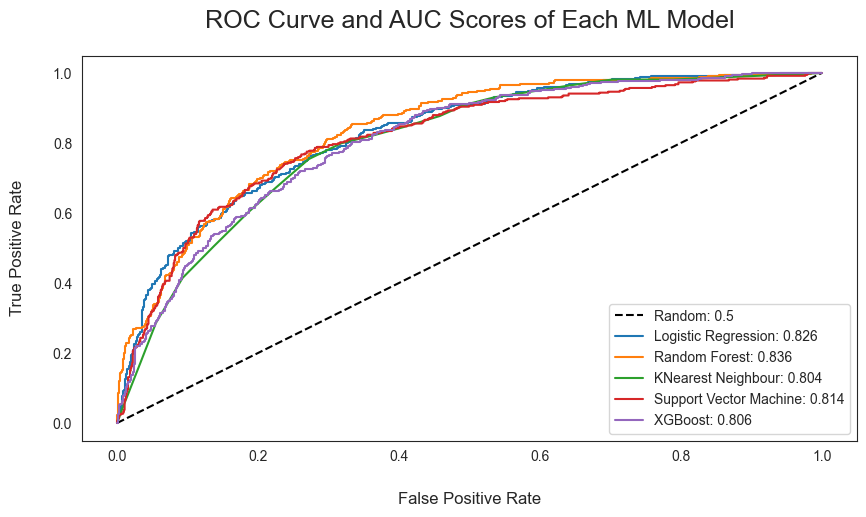

In [69]:
plt.figure(figsize=(10,5))

plt.plot([0, 1], [0, 1], 'k--', label='Random: 0.5')
plt.plot(log_model_roc[0], log_model_roc[1], label=f'Logistic Regression: {round(log_model_roc[2], 3)}')
plt.plot(rf_model_roc[0], rf_model_roc[1], label=f'Random Forest: {round(rf_model_roc[2], 3)}')
plt.plot(knn_model_roc[0], knn_model_roc[1], label=f'KNearest Neighbour: {round(knn_model_roc[2], 3)}')
plt.plot(svm_model_roc[0], svm_model_roc[1], label=f'Support Vector Machine: {round(svm_model_roc[2], 3)}')
plt.plot(xgb_model_roc[0], xgb_model_roc[1], label=f'XGBoost: {round(xgb_model_roc[2], 3)}')

plt.xlabel('False Positive Rate', size=12, labelpad=20)
plt.ylabel('True Positive Rate', size=12, labelpad=20)
plt.title('ROC Curve and AUC Scores of Each ML Model', size=18, pad=20)

plt.legend()

plt.show()

The above graph shows the ROC curves of each ML model built and their corresponding AUC scores. Although all the AUC scores are quite similar, we can say the Random Forest Classifier was the best predictor of customer churn. However, if we also consider the recall value together with the AUC, then KNearest Neighbour is the clear winner with an AUC of 0.8 and Recall of 0.83.

The scores can be improved further by tuning the hyperparameters of the models, getting more data instead of oversampling, trying different combinations of models, including ensemble ones etc. However, they are not in the scope of this project and has been left out.

With that we have concluded this project.

Suggestion

As stated previously, churn is a one of the biggest problem in the telecom industry. In order to reduce churning, a company can:

Focus their attention on the best customers: Rather than simply focusing on offering incentives to customers who are considering churning, it could be even more beneficial to pool resources into the loyal, profitable customers.


Analyze churn as it occurs: Analyze how and when churn occurs in a customer's lifetime with the company, and use that data to put into place preemptive measures.


Show the customers that they care: Instead of waiting to connect with the customers until they reach out, they should try a more proactive approach to show them that the company cares about their experience, and they'll be sure to stick around.